# Clustering Indian Districts by Seasonal Crop-Production Profile

**Student:** Radhika  
**University Roll No.:** 24020570050  
**Problem No.:** 4  
**Domain:** Agriculture  
**SDGs:** SDG 2 – Zero Hunger; SDG 15 – Life on Land  
**Article type:** Case Study

## 1. Problem and objective

Agricultural policy is often uniform although districts differ in what and when they grow. This case study groups Indian districts by the share of cultivated area and crop production associated with **Kharif, Rabi and Whole Year** crops. The objective is to discover interpretable agro-production zones that may help planners tailor agricultural extension services.

The notebook implements the methods specified in the allocation:

- K-Means, using the Elbow Method and Silhouette Score to examine the number of clusters;
- Agglomerative Hierarchical Clustering with Ward linkage (Euclidean distance);
- Agglomerative clustering using cosine distance (average linkage, because Ward linkage is defined for Euclidean geometry);
- PCA for two-dimensional visualisation;
- Silhouette Score, Davies–Bouldin Index and cluster profiles for evaluation.

> **Important:** This is an unsupervised case study. Cluster labels are groups discovered by an algorithm, not ground-truth agricultural categories. Recommendations must be interpreted as exploratory planning insights, not causal claims.

## 2. Dataset and source

The supplied dataset is a Kaggle copy of the India crop-production dataset, whose seven fields are `State_Name`, `District_Name`, `Crop_Year`, `Season`, `Crop`, `Area` and `Production`. The allocated official source is the Government of India's Open Government Data Platform resource published by the Directorate of Economics & Statistics, Ministry of Agriculture & Farmers Welfare:

- Official resource: https://www.data.gov.in/resource/district-wise-season-wise-crop-production-statistics-1997
- Kaggle copy used in this notebook: https://www.kaggle.com/datasets/abhinand05/crop-production-in-india

The dataset file is included in this project under `data/`.

In [ ]:
# 2.1 Imports and reproducibility
from pathlib import Path
import zipfile
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score

RANDOM_STATE = 42
SEASONS = ["Kharif", "Rabi", "Whole Year"]
ID_COLS = ["State_Name", "District_Name"]
FEATURE_COLS = [
    "AreaShare_Kharif", "AreaShare_Rabi", "AreaShare_Whole_Year",
    "ProductionShare_Kharif", "ProductionShare_Rabi", "ProductionShare_Whole_Year"
]

# Works when launched from the project root or from the notebooks directory.
CANDIDATE_PATHS = [
    Path("data/crop_production.csv.zip"),
    Path("../data/crop_production.csv.zip"),
    Path("crop_production.csv.zip"),
    Path("../crop_production.csv.zip")
]
DATA_PATH = next((p for p in CANDIDATE_PATHS if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Dataset not found. Keep data/crop_production.csv.zip beside this notebook's project folder.")

OUTPUT_DIR = Path("results")
if not OUTPUT_DIR.exists() and Path("../results").exists():
    OUTPUT_DIR = Path("../results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset:", DATA_PATH.resolve())
print("Results directory:", OUTPUT_DIR.resolve())

Dataset: /mnt/data/radhika_crop_clustering_project/data/crop_production.csv.zip
Results directory: /mnt/data/radhika_crop_clustering_project/results


## 3. Load and inspect the data

The first checks document the dataset's size, fields, missing values, duplicates, year coverage, season categories and district coverage. District identity is represented by the pair `(State_Name, District_Name)` because district names alone are not guaranteed to be unique.

In [ ]:
# 3.1 Load CSV directly from the supplied ZIP archive
with zipfile.ZipFile(DATA_PATH) as zf:
    csv_members = [name for name in zf.namelist() if name.lower().endswith(".csv")]
    if not csv_members:
        raise ValueError("No CSV file found inside the dataset ZIP archive.")
    with zf.open(csv_members[0]) as csv_file:
        raw = pd.read_csv(csv_file)

required_columns = {"State_Name", "District_Name", "Crop_Year", "Season", "Crop", "Area", "Production"}
missing_columns = required_columns - set(raw.columns)
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {sorted(missing_columns)}")

print(f"Rows: {len(raw):,} | Columns: {len(raw.columns)}")
display(raw.head())
display(pd.DataFrame({
    "Data type": raw.dtypes.astype(str),
    "Missing values": raw.isna().sum(),
    "Missing (%)": (raw.isna().mean() * 100).round(2)
}))
print("Exact duplicate rows:", int(raw.duplicated().sum()))
print("Unique states/UTs:", raw["State_Name"].nunique())
print("Unique district-name strings:", raw["District_Name"].nunique())
print("Unique state-district pairs:", raw[ID_COLS].drop_duplicates().shape[0])
print("Unique crops:", raw["Crop"].nunique())
print("Year range:", raw["Crop_Year"].min(), "to", raw["Crop_Year"].max())

Rows: 246,091 | Columns: 7


,State_Name,District_Name,Crop_Year,Season,Crop,Area,Production
0,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Arecanut,1254.0,2000.0
1,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Other Kharif pulses,2.0,1.0
2,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Rice,102.0,321.0
3,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Banana,176.0,641.0
4,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Cashewnut,720.0,165.0


,Data type,Missing values,Missing (%)
State_Name,object,0,0.00
District_Name,object,0,0.00
Crop_Year,int64,0,0.00
Season,object,0,0.00
Crop,object,0,0.00
Area,float64,0,0.00
Production,float64,3730,1.52


Exact duplicate rows: 0
Unique states/UTs: 33
Unique district-name strings: 646
Unique state-district pairs: 652
Unique crops: 124
Year range: 1997 to 2015


,Season,Records
0,Kharif,95951
1,Rabi,66987
2,Whole Year,57305
3,Summer,14841
4,Winter,6058
5,Autumn,4949


,Crop_Year,Records
11,2008,14550
12,2009,14116
13,2010,14065
14,2011,14071
15,2012,13410
16,2013,13650
17,2014,10973
18,2015,562


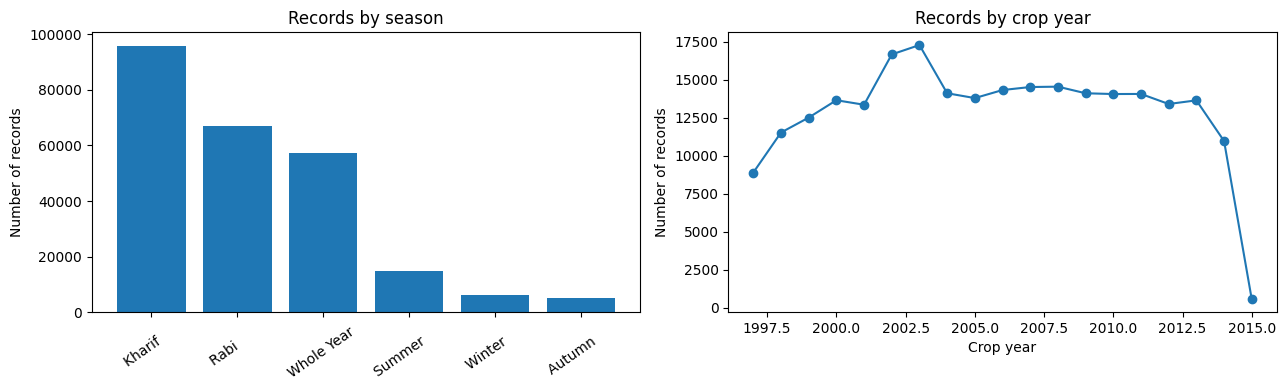

In [ ]:
# 3.2 Season and year coverage
season_counts = raw["Season"].value_counts(dropna=False).rename_axis("Season").reset_index(name="Records")
year_counts = raw["Crop_Year"].value_counts().sort_index().rename_axis("Crop_Year").reset_index(name="Records")
display(season_counts)
display(year_counts.tail(8))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(season_counts["Season"].astype(str), season_counts["Records"])
axes[0].set_title("Records by season")
axes[0].set_ylabel("Number of records")
axes[0].tick_params(axis="x", rotation=35)
axes[1].plot(year_counts["Crop_Year"], year_counts["Records"], marker="o")
axes[1].set_title("Records by crop year")
axes[1].set_xlabel("Crop year")
axes[1].set_ylabel("Number of records")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "00_dataset_overview.png", dpi=180, bbox_inches="tight")
plt.show()

## 4. Data cleaning and feature engineering

### 4.1 Analysis scope

The allocated problem specifically names **Kharif, Rabi and Whole Year**. Autumn, Summer and Winter are therefore excluded from the primary analysis and recorded as a scope limitation. The file contains only 562 rows for 2015, compared with 10,973 rows for 2014; the primary analysis is restricted to 1997–2014 to avoid allowing a visibly incomplete final year to distort long-run seasonal totals. This choice will be disclosed in the report.

### 4.2 Seasonal features

Six features are constructed for each state-district unit:

1. Three **area shares**: seasonal cultivated area divided by the district's total cultivated area across the three included seasons.
2. Three **production shares**: production is first normalised within each district–crop across seasons, then crop-level seasonal shares are averaged equally within the district.

The dataset does not identify a common production unit across all crop types. Therefore, raw production quantities from different crops are **not** added together. The crop-normalised production share is a relative seasonal-composition proxy; equal crop weighting means it should not be interpreted as a district's absolute production contribution.

Records with missing/non-positive area are excluded from area features. Missing production values are omitted from the production calculation. Districts represented in fewer than two of the three target seasons are excluded from clustering. Missing feature values after aggregation are set to zero only where a district has no observed contribution for that season; this is a modelling convention and is disclosed.

In [ ]:
# 4.1 Clean data types and filter the allocated period and seasons
df = raw.copy()
for col in ["State_Name", "District_Name", "Season", "Crop"]:
    df[col] = df[col].astype("string").str.strip()

df["Crop_Year"] = pd.to_numeric(df["Crop_Year"], errors="coerce")
df["Area"] = pd.to_numeric(df["Area"], errors="coerce")
df["Production"] = pd.to_numeric(df["Production"], errors="coerce")

analysis = df[
    df["Crop_Year"].between(1997, 2014) & df["Season"].isin(SEASONS)
].copy()
analysis = analysis.dropna(subset=ID_COLS + ["Crop", "Crop_Year", "Area"])
analysis = analysis[analysis["Area"] > 0]

print(f"Rows retained after year/season/area filtering: {len(analysis):,}")
print("Included seasons:", sorted(analysis["Season"].dropna().unique().tolist()))
print("Missing production in filtered analysis:", int(analysis["Production"].isna().sum()))

Rows retained after year/season/area filtering: 220,208
Included seasons: ['Kharif', 'Rabi', 'Whole Year']
Missing production in filtered analysis: 3673


In [ ]:
# 4.2 Area shares by state-district
area_totals = (
    analysis.groupby(ID_COLS + ["Season"], observed=True)["Area"]
    .sum()
    .unstack(fill_value=0)
    .reindex(columns=SEASONS, fill_value=0)
)
area_shares = area_totals.div(area_totals.sum(axis=1).replace(0, np.nan), axis=0)
area_shares.columns = [f"AreaShare_{s.replace(' ', '_')}" for s in area_shares.columns]

# 4.3 Crop-normalised seasonal production shares
production_data = analysis.dropna(subset=["Production"])
production_data = production_data[production_data["Production"] >= 0]

crop_season_production = (
    production_data.groupby(ID_COLS + ["Crop", "Season"], observed=True)["Production"]
    .sum(min_count=1)
    .unstack(fill_value=0)
    .reindex(columns=SEASONS, fill_value=0)
)
crop_totals = crop_season_production.sum(axis=1).replace(0, np.nan)
crop_season_shares = crop_season_production.div(crop_totals, axis=0).dropna(how="all")
production_shares = crop_season_shares.groupby(level=ID_COLS).mean()
production_shares = production_shares.div(production_shares.sum(axis=1).replace(0, np.nan), axis=0)
production_shares.columns = [f"ProductionShare_{s.replace(' ', '_')}" for s in production_shares.columns]

# 4.4 Coverage metadata and final feature matrix
coverage = analysis.groupby(ID_COLS).agg(
    Years_Observed=("Crop_Year", "nunique"),
    Records=("Crop_Year", "size"),
    Seasons_Observed=("Season", "nunique"),
    Crops_Observed=("Crop", "nunique")
)
features = area_shares.join(production_shares, how="left").join(coverage, how="left")
features = features.replace([np.inf, -np.inf], np.nan)
features[FEATURE_COLS] = features[FEATURE_COLS].fillna(0)
features = features[features["Seasons_Observed"] >= 2].reset_index()

print(f"Districts represented in filtered data: {coverage.shape[0]:,}")
print(f"Districts retained for clustering (at least 2 target seasons): {len(features):,}")
print(f"Districts excluded for insufficient season coverage: {coverage.shape[0] - len(features):,}")
display(features.head())
display(features[FEATURE_COLS].describe().T)

Districts represented in filtered data: 651
Districts retained for clustering (at least 2 target seasons): 643
Districts excluded for insufficient season coverage: 8


,State_Name,District_Name,AreaShare_Kharif,AreaShare_Rabi,AreaShare_Whole_Year,ProductionShare_Kharif,ProductionShare_Rabi,ProductionShare_Whole_Year,Years_Observed,Records,Seasons_Observed,Crops_Observed
0,Andaman and Nicobar Islands,NICOBARS,0.019697,0.013275,0.967028,0.140263,0.247241,0.612496,8,77,3,17
1,Andaman and Nicobar Islands,NORTH AND MIDDLE ANDAMAN,0.512041,0.069575,0.418384,0.133159,0.389826,0.477015,4,48,3,20
2,Andaman and Nicobar Islands,SOUTH ANDAMANS,0.378096,0.025277,0.596627,0.052632,0.362575,0.584794,6,72,3,19
3,Andhra Pradesh,ANANTAPUR,0.853834,0.121931,0.024235,0.517034,0.203536,0.279430,18,788,3,60
4,Andhra Pradesh,CHITTOOR,0.677329,0.202442,0.120229,0.472710,0.233469,0.293821,18,789,3,59


,count,mean,std,min,25%,50%,75%,max
AreaShare_Kharif,643.0,0.526042,0.272516,0.0,0.359435,0.523134,0.756160,0.985529
AreaShare_Rabi,643.0,0.347262,0.269256,0.0,0.104687,0.335117,0.525220,0.996702
AreaShare_Whole_Year,643.0,0.126696,0.187665,0.0,0.017767,0.059558,0.148565,0.999997
ProductionShare_Kharif,643.0,0.423607,0.134034,0.0,0.360569,0.437384,0.499631,0.857143
ProductionShare_Rabi,643.0,0.286293,0.150641,0.0,0.219382,0.277778,0.354282,0.982967
ProductionShare_Whole_Year,643.0,0.290099,0.182767,0.0,0.158142,0.279060,0.342034,0.954545


In [ ]:
# 4.5 Check that each three-part share composition sums to approximately one
features["AreaShare_Sum"] = features[["AreaShare_Kharif", "AreaShare_Rabi", "AreaShare_Whole_Year"]].sum(axis=1)
features["ProductionShare_Sum"] = features[["ProductionShare_Kharif", "ProductionShare_Rabi", "ProductionShare_Whole_Year"]].sum(axis=1)
print("Area share sum range:", features["AreaShare_Sum"].min(), "to", features["AreaShare_Sum"].max())
print("Production share sum range:", features["ProductionShare_Sum"].min(), "to", features["ProductionShare_Sum"].max())
features = features.drop(columns=["AreaShare_Sum", "ProductionShare_Sum"])

# Export the engineered dataset for audit/reuse
features.to_csv(OUTPUT_DIR / "district_seasonal_features.csv", index=False)

Area share sum range: 0.9999999999999999 to 1.0000000000000002
Production share sum range: 0.9999999999999999 to 1.0000000000000002


## 5. Scaling and K-Means model selection

The six seasonal-share features are standardised before distance-based clustering so that the area-share and production-share dimensions contribute on comparable standardised scales. K-Means is fitted for candidate values of *k* from 2 to 10. The Elbow Method examines within-cluster sum of squares (inertia), while the Silhouette Score measures separation and compactness. The selected *k* is the candidate with the highest silhouette score in the tested range; the elbow curve and agricultural interpretability are also considered rather than treating this numerical rule as an absolute truth.

,k,Inertia,Silhouette_Euclidean
0,2,2738.201236,0.408242
1,3,1900.033024,0.329052
2,4,1441.607270,0.361450
3,5,1168.491151,0.363584
4,6,943.867981,0.348351
5,7,800.703451,0.355078
6,8,690.519993,0.370549
7,9,605.651274,0.363145
8,10,553.054523,0.356949


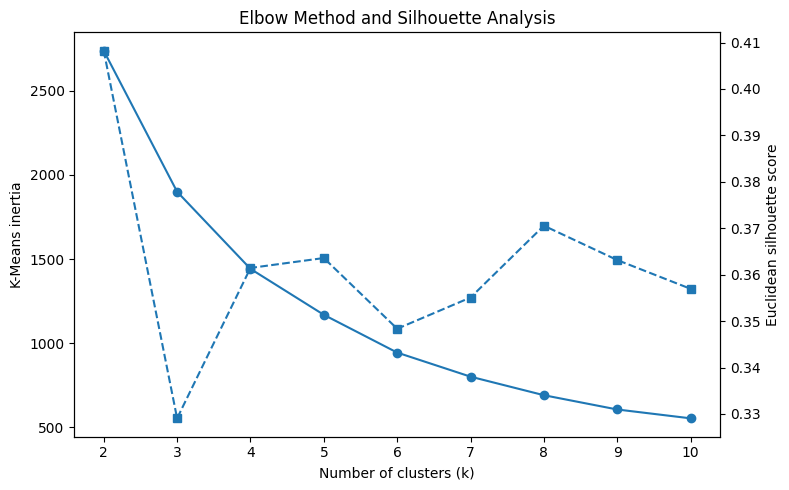

Selected k by maximum tested Euclidean silhouette: 2


In [ ]:
# 5.1 Standardise the six clustering features
scaler = StandardScaler()
X = scaler.fit_transform(features[FEATURE_COLS].astype(float))

# 5.2 Elbow and silhouette analysis
k_values = list(range(2, min(10, len(features) - 1) + 1))
inertias, silhouettes = [], []
for k in k_values:
    candidate = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    candidate_labels = candidate.fit_predict(X)
    inertias.append(float(candidate.inertia_))
    silhouettes.append(float(silhouette_score(X, candidate_labels, metric="euclidean")))

k_diagnostics = pd.DataFrame({"k": k_values, "Inertia": inertias, "Silhouette_Euclidean": silhouettes})
display(k_diagnostics)

fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(k_values, inertias, marker="o", label="Inertia")
ax1.set_xlabel("Number of clusters (k)")
ax1.set_ylabel("K-Means inertia")
ax1.set_title("Elbow Method and Silhouette Analysis")
ax2 = ax1.twinx()
ax2.plot(k_values, silhouettes, marker="s", linestyle="--", label="Silhouette")
ax2.set_ylabel("Euclidean silhouette score")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "01_elbow_silhouette.png", dpi=180, bbox_inches="tight")
plt.show()

best_k = k_values[int(np.argmax(silhouettes))]
print(f"Selected k by maximum tested Euclidean silhouette: {best_k}")

## 6. Clustering models

Three clustering configurations are compared:

1. **K-Means (Euclidean):** centroid-based partitioning.
2. **Agglomerative (Ward/Euclidean):** hierarchical bottom-up clustering using Ward's minimum-variance linkage.
3. **Agglomerative (Average/Cosine):** hierarchical clustering with average linkage and cosine distance. Ward linkage is not paired with cosine distance because Ward's criterion is based on Euclidean variance minimisation.

All models use the same selected number of clusters to make the comparison easier to interpret. For each set of labels, both Euclidean and cosine silhouette scores are reported. Davies–Bouldin is reported in the standard Euclidean feature space; it is not a cosine-distance metric.

In [ ]:
# 6.1 Fit the three required clustering approaches
kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=20)
kmeans_labels = kmeans.fit_predict(X)

ward_model = AgglomerativeClustering(n_clusters=best_k, linkage="ward", metric="euclidean")
ward_labels = ward_model.fit_predict(X)

cosine_model = AgglomerativeClustering(n_clusters=best_k, linkage="average", metric="cosine")
cosine_labels = cosine_model.fit_predict(X)

print("K-Means cluster labels:", np.unique(kmeans_labels))
print("Ward cluster labels:", np.unique(ward_labels))
print("Cosine hierarchical cluster labels:", np.unique(cosine_labels))

K-Means cluster labels: [0 1]
Ward cluster labels: [0 1]
Cosine hierarchical cluster labels: [0 1]


In [ ]:
# 6.2 Evaluation metrics: Silhouette (Euclidean and cosine), Davies-Bouldin
model_labels = {
    "K-Means (Euclidean)": kmeans_labels,
    "Agglomerative (Ward/Euclidean)": ward_labels,
    "Agglomerative (Average/Cosine)": cosine_labels
}
metric_rows = []
for model_name, labels in model_labels.items():
    metric_rows.append({
        "Model": model_name,
        "k": best_k,
        "Silhouette_Euclidean": silhouette_score(X, labels, metric="euclidean"),
        "Silhouette_Cosine": silhouette_score(X, labels, metric="cosine"),
        "Davies_Bouldin_Euclidean": davies_bouldin_score(X, labels)
    })

model_evaluation = pd.DataFrame(metric_rows)
display(model_evaluation.round(4))
model_evaluation.to_csv(OUTPUT_DIR / "model_evaluation.csv", index=False)

,Model,k,Silhouette_Euclidean,Silhouette_Cosine,Davies_Bouldin_Euclidean
0,K-Means (Euclidean),2,0.4082,0.2757,1.0664
1,Agglomerative (Ward/Euclidean),2,0.4615,0.1785,0.8936
2,Agglomerative (Average/Cosine),2,0.2956,0.5363,1.3412


## 7. PCA visualisation

PCA reduces the six standardised seasonal-share features to two principal components for visual inspection. The scatter plot below colours districts by their K-Means cluster. PCA is used for visualisation; clustering is performed on the original six standardised features, not on the two-dimensional PCA projection.

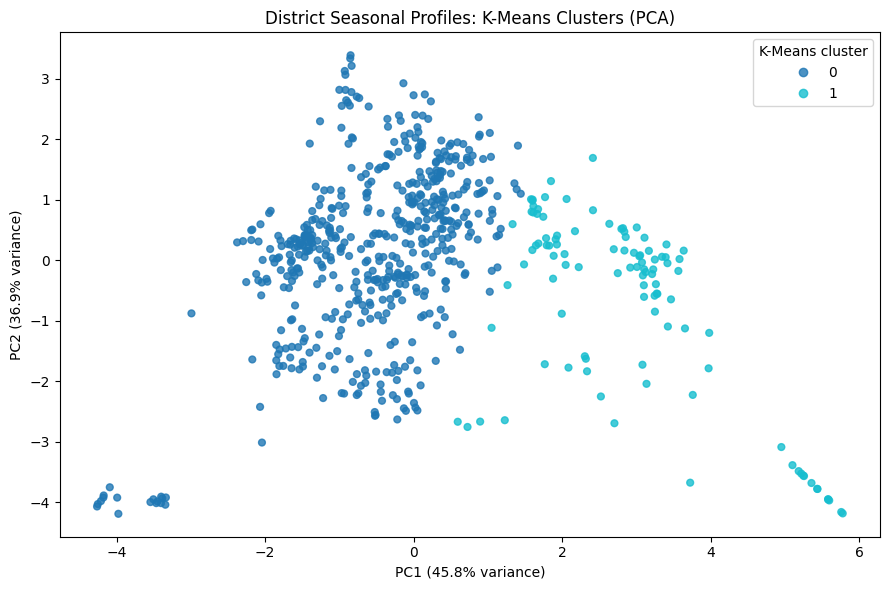

Explained variance by first two PCs: 82.69%


In [ ]:
# 7.1 PCA projection of the standardised six-dimensional feature space
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X)
explained = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(9, 6))
scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap="tab10", s=24, alpha=0.8)
ax.set_xlabel(f"PC1 ({explained[0]*100:.1f}% variance)")
ax.set_ylabel(f"PC2 ({explained[1]*100:.1f}% variance)")
ax.set_title("District Seasonal Profiles: K-Means Clusters (PCA)")
ax.legend(*scatter.legend_elements(), title="K-Means cluster")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "02_pca_clusters.png", dpi=180, bbox_inches="tight")
plt.show()
print(f"Explained variance by first two PCs: {explained.sum()*100:.2f}%")

# Save a reusable PCA coordinates table
pca_results = features[ID_COLS].copy()
pca_results["PC1"] = X_pca[:, 0]
pca_results["PC2"] = X_pca[:, 1]
pca_results["KMeans_Cluster"] = kmeans_labels
pca_results.to_csv(OUTPUT_DIR / "pca_coordinates.csv", index=False)

## 8. Cluster profiles and district assignments

Cluster profiles are the mean of each seasonal share feature within each K-Means cluster. They help describe the seasonal composition of each group. Cluster numbers are arbitrary identifiers: Cluster 0 is not inherently better or worse than Cluster 1. Profiles should be interpreted alongside district membership and coverage.

In [ ]:
# 8.1 Cluster assignments for all three algorithms
assignments = features[ID_COLS + ["Years_Observed", "Records", "Seasons_Observed", "Crops_Observed"]].copy()
assignments["KMeans_Cluster"] = kmeans_labels
assignments["Ward_Cluster"] = ward_labels
assignments["Cosine_Cluster"] = cosine_labels
assignments.to_csv(OUTPUT_DIR / "district_cluster_assignments.csv", index=False)

# 8.2 K-Means cluster profiles and sizes
profile_data = features[ID_COLS + FEATURE_COLS].copy()
profile_data["Cluster"] = kmeans_labels
cluster_profiles = profile_data.groupby("Cluster")[FEATURE_COLS].mean().reset_index()
cluster_sizes = assignments["KMeans_Cluster"].value_counts().sort_index().rename_axis("Cluster").reset_index(name="District_Count")
display(cluster_sizes)
display(cluster_profiles.round(4))
cluster_profiles.to_csv(OUTPUT_DIR / "cluster_profiles.csv", index=False)
cluster_sizes.to_csv(OUTPUT_DIR / "cluster_sizes.csv", index=False)

,Cluster,District_Count
0,0,538
1,1,105


,Cluster,AreaShare_Kharif,AreaShare_Rabi,AreaShare_Whole_Year,ProductionShare_Kharif,ProductionShare_Rabi,ProductionShare_Whole_Year
0,0,0.5230,0.4054,0.0716,0.4506,0.3209,0.2286
1,1,0.5414,0.0495,0.4091,0.2855,0.1092,0.6053


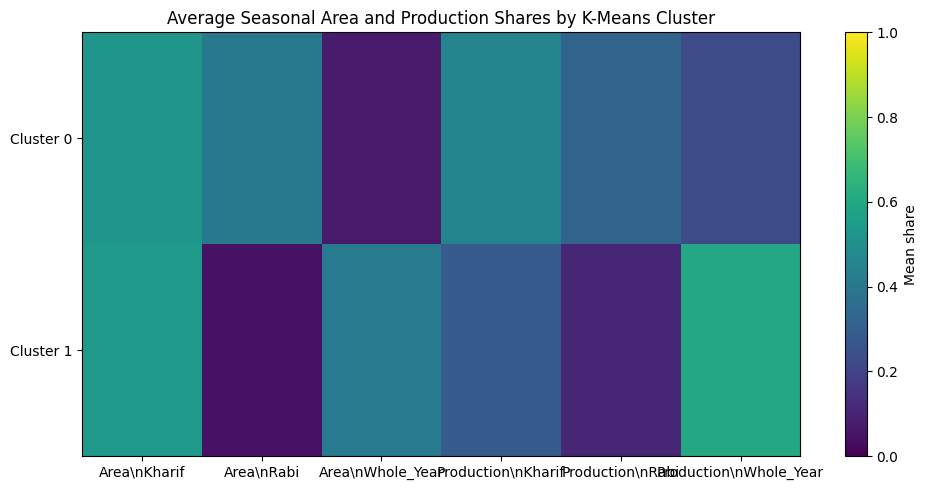

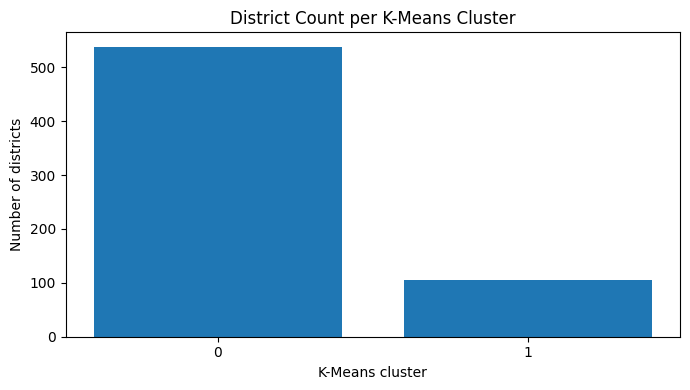

In [ ]:
# 8.3 Visualise seasonal profiles and cluster sizes
fig, ax = plt.subplots(figsize=(10, 5))
image = ax.imshow(cluster_profiles[FEATURE_COLS].values, aspect="auto", vmin=0, vmax=1)
ax.set_yticks(range(len(cluster_profiles)), [f"Cluster {int(c)}" for c in cluster_profiles["Cluster"]])
ax.set_xticks(range(len(FEATURE_COLS)), [c.replace("Share_", "\\n") for c in FEATURE_COLS])
ax.set_title("Average Seasonal Area and Production Shares by K-Means Cluster")
fig.colorbar(image, ax=ax, label="Mean share")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "03_cluster_profiles.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(cluster_sizes["Cluster"].astype(str), cluster_sizes["District_Count"])
ax.set_xlabel("K-Means cluster")
ax.set_ylabel("Number of districts")
ax.set_title("District Count per K-Means Cluster")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "04_cluster_sizes.png", dpi=180, bbox_inches="tight")
plt.show()

## 9. Interpretation for agricultural planning

Use the generated cluster profile table to describe which seasons have relatively larger area and production shares in each group. Possible planning implications include tailoring seasonal advisories, extension-service calendars, irrigation planning discussions and crop-specific outreach. These are **potential applications**, not recommendations validated by causal or impact evaluation.

A cluster should be named only after reviewing its measured profile. Avoid labels such as “high productivity” unless productivity is explicitly measured with an appropriate crop-specific yield measure. This dataset's mixed crop production units make cross-crop absolute production comparisons inappropriate.

In [ ]:
# 9.1 Create a concise, data-grounded text summary for each cluster
for _, row in cluster_profiles.iterrows():
    cluster_id = int(row["Cluster"])
    area_values = {s: row[f"AreaShare_{s.replace(' ', '_')}"] for s in SEASONS}
    prod_values = {s: row[f"ProductionShare_{s.replace(' ', '_')}"] for s in SEASONS}
    dominant_area = max(area_values, key=area_values.get)
    dominant_prod = max(prod_values, key=prod_values.get)
    district_count = int(cluster_sizes.loc[cluster_sizes["Cluster"] == cluster_id, "District_Count"].iloc[0])
    print(f"Cluster {cluster_id}: {district_count} districts")
    print(f"  Largest mean area share: {dominant_area} ({area_values[dominant_area]:.3f})")
    print(f"  Largest mean crop-normalised production share: {dominant_prod} ({prod_values[dominant_prod]:.3f})")

Cluster 0: 538 districts
  Largest mean area share: Kharif (0.523)
  Largest mean crop-normalised production share: Kharif (0.451)
Cluster 1: 105 districts
  Largest mean area share: Kharif (0.541)
  Largest mean crop-normalised production share: Whole Year (0.605)


## 10. Limitations and responsible interpretation

1. **Partial 2015 coverage:** 2015 has far fewer records than the preceding year and is excluded from the main analysis.
2. **Season scope:** Autumn, Summer and Winter are not part of the primary analysis because the assigned problem specifies Kharif, Rabi and Whole Year.
3. **Production units:** The dataset does not establish a common unit across crops. Production features are therefore crop-normalised seasonal shares, not total tonnage shares.
4. **Unequal crop weighting:** Averaging crop-level shares gives each crop equal weight within a district. This is a deliberate relative-profile choice and may differ from an area- or output-weighted profile.
5. **District boundary changes:** Historical district names and boundaries may have changed between 1997 and 2014; the dataset does not provide a harmonised boundary crosswalk.
6. **Coverage differences:** Districts have different numbers of observations, years and crops. Coverage metadata is retained for interpretation.
7. **Clustering is exploratory:** No ground-truth agro-ecological zone labels are supplied. Internal metrics measure geometric structure, not policy effectiveness.
8. **Feature scaling and composition:** StandardScaler is used to follow a conventional syllabus workflow. Because the features are shares that sum to one within each feature family, alternative compositional-data methods could be explored in future work.

The project relates to **SDG 2 (Zero Hunger)** through the potential to support more locally tailored agricultural planning, and **SDG 15 (Life on Land)** through the possibility of region-sensitive crop and land-use advisory planning. The analysis does not itself demonstrate improvements in food security or biodiversity.

## 11. Export final results and reproducibility summary

The following files are written to the `results/` folder and can be used when preparing the six-page journal paper. Report only values generated by this notebook.

In [ ]:
# 11.1 Save all key outputs and a machine-readable run summary
summary = {
    "student": "Radhika",
    "university_roll_no": "24020570050",
    "problem_no": 4,
    "raw_rows": int(len(raw)),
    "raw_columns": list(raw.columns),
    "raw_missing_production": int(raw["Production"].isna().sum()),
    "raw_exact_duplicates": int(raw.duplicated().sum()),
    "year_scope": "1997-2014 (2015 excluded due to markedly lower record count)",
    "included_seasons": SEASONS,
    "analysis_rows": int(len(analysis)),
    "districts_clustered": int(len(features)),
    "districts_excluded_for_insufficient_season_coverage": int(coverage.shape[0] - len(features)),
    "selected_k_by_maximum_tested_euclidean_silhouette": int(best_k),
    "pca_explained_variance_first_two_components": float(explained.sum()),
    "k_diagnostics": k_diagnostics.to_dict(orient="records"),
    "model_evaluation": model_evaluation.to_dict(orient="records"),
    "feature_method": "Area shares by district-season; production shares normalised within district-crop across seasons then equally averaged across crops.",
    "limitations": [
        "2015 excluded due to markedly lower record count.",
        "Only Kharif, Rabi and Whole Year included per allocated problem.",
        "Production units are not documented as common across crop types.",
        "Historical district boundaries may have changed.",
        "Clustering is exploratory and has no ground-truth labels."
    ]
}
(OUTPUT_DIR / "run_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")

print("Saved files:")
for path in sorted(OUTPUT_DIR.iterdir()):
    if path.is_file():
        print(f" - {path.name} ({path.stat().st_size:,} bytes)")

print("\nFinal model comparison:")
display(model_evaluation.round(4))

Saved files:
 - 00_dataset_overview.png (107,005 bytes)
 - 01_elbow_silhouette.png (104,770 bytes)
 - 02_pca_clusters.png (286,933 bytes)
 - 03_cluster_profiles.png (58,224 bytes)
 - 04_cluster_sizes.png (33,490 bytes)
 - cluster_profiles.csv (372 bytes)
 - cluster_sizes.csv (35 bytes)
 - district_cluster_assignments.csv (24,617 bytes)
 - district_seasonal_features.csv (94,041 bytes)
 - model_evaluation.csv (330 bytes)
 - pca_coordinates.csv (39,576 bytes)
 - run_summary.json (2,937 bytes)

Final model comparison:


,Model,k,Silhouette_Euclidean,Silhouette_Cosine,Davies_Bouldin_Euclidean
0,K-Means (Euclidean),2,0.4082,0.2757,1.0664
1,Agglomerative (Ward/Euclidean),2,0.4615,0.1785,0.8936
2,Agglomerative (Average/Cosine),2,0.2956,0.5363,1.3412


## 12. Conclusion

This notebook builds a reproducible district-level clustering workflow using seasonal area and crop-normalised production shares. It compares K-Means with Ward and cosine-based agglomerative clustering, uses Elbow and Silhouette analysis for K-Means model selection, evaluates clusters with Silhouette and Davies–Bouldin metrics, and visualises the resulting groups using PCA. The final case-study conclusions must be based on the cluster profile tables and the actual outputs produced above.